# Plate Reader Training — Paper Setup

Reproduces the plate reading model of Hasin et al. (2026) on `bangla-plate-reading`: a vision encoder-decoder that reads the plate text directly from the crop.

**As described in the paper**
- ViT-Base encoder, Transformer decoder with the BanglaBERT tokenizer.
- AdamW, learning rate 5e-5, batch size 6, mixed precision (fp16), 7,800 training iterations.
- Beam search with width 3; repeated n-grams are allowed (plates repeat digits).
- Metrics: character error rate (CER) and word error rate (WER).

**Not stated in the paper, chosen here:** encoder `google/vit-base-patch16-224-in21k` (224 × 224 input); decoder initialised from `csebuetnlp/banglabert` with new cross-attention layers; text normalised with the BanglaBERT normaliser; maximum length 32 tokens; no warm-up or weight decay (Trainer defaults); one GPU, so the batch stays at 6.

**Data:** the paper's MMHQ dataset is no longer available, so the model is trained and tested on our splits. The text label of each crop is built from its character boxes (place names and series letter, then the digits, each left to right), e.g. `ঢাকা মেট্রো গ ১২-৩৪৫৬`. Results are therefore not directly comparable with the paper's 13.23% CER, but are comparable with our YOLO reader on the same test split.

**Setup (Kaggle notebook)**
1. Add `bangla-plate-reading` as an input.
2. Accelerator: **GPU**. Internet: **on** (model download).

In [1]:
%pip install -q git+https://github.com/csebuetnlp/normalizer

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.0/185.0 kB 647.2 kB/s eta 0:00:0000:01
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.2/64.2 kB 3.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
Note: you may need to restart the kernel to use updated packages.


## Configuration

In [2]:
EXPERIMENT = "vit-banglabert-paper"

ENCODER = "google/vit-base-patch16-224-in21k"
DECODER = "csebuetnlp/banglabert"
BATCH = 6
LEARNING_RATE = 5e-5
MAX_STEPS = 7800
NUM_BEAMS = 3
MAX_LENGTH = 32
SEED = 0

## Setup

In [3]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"   # one GPU, so the batch size stays at 6

import json
import re
import shutil
from pathlib import Path

import pandas as pd
import torch
from normalizer import normalize
from PIL import Image
from transformers import (AutoTokenizer, Seq2SeqTrainer, Seq2SeqTrainingArguments, ViTImageProcessor,
                          VisionEncoderDecoderModel, set_seed)

set_seed(SEED)
WORK = Path("/kaggle/working")
INPUT = Path("/kaggle/input")
RUN = WORK / "runs" / EXPERIMENT
RUN.mkdir(parents=True, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

DATA = next(p for p in INPUT.rglob("bangla-plate-reading") if p.is_dir())
CLASSES = json.loads((DATA / "classes.json").read_text(encoding="utf-8"))
print("Data:", DATA, "| device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

Data: /kaggle/input/datasets/raahad/bangla-plate-reading | device: cuda Tesla T4


## Text labels

Each crop's character boxes are turned into its plate text: the place names, `Metro` and the series letter form the top line and the digits the bottom line, each read left to right (so tilted plates keep their order), and six digits are written as `12-3456`. The same function is used to score the YOLO reader.

In [6]:
BANGLA = [c["bangla"] for c in CLASSES]
KIND = [c["kind"] for c in CLASSES]


def plate_text(boxes):
    # boxes: (class, x_center, y_center, width, height), normalised.
    # Top line: place names, Metro and the series letter, left to right; bottom line: digits, left to right.
    # Using the class kind instead of the vertical position keeps tilted plates in the right order.
    head = [b for b in sorted(boxes, key=lambda b: b[1]) if KIND[int(b[0])] != "digit"]
    digits = "".join(BANGLA[int(b[0])] for b in sorted(boxes, key=lambda b: b[1]) if KIND[int(b[0])] == "digit")
    if len(digits) == 6:
        digits = f"{digits[:2]}-{digits[2:]}"
    return " ".join(part for part in (" ".join(BANGLA[int(b[0])] for b in head), digits) if part)


def clean(text: str) -> str:
    # one space between words, none around the hyphen; applied to labels and predictions alike
    return re.sub(r"\s*-\s*", "-", " ".join(normalize(text).split()))


def load_split(split: str) -> pd.DataFrame:
    rows = []
    for image in sorted((DATA / "images" / split).iterdir()):
        label = DATA / "labels" / split / f"{image.stem}.txt"
        boxes = [(int(p[0]), *map(float, p[1:])) for p in (l.split() for l in label.read_text().splitlines()) if p]
        rows.append({"image": str(image), "source": image.name.split("__")[0], "text": clean(plate_text(boxes))})
    return pd.DataFrame(rows)


splits = {split: load_split(split) for split in ("train", "val", "test")}
for split, df in splits.items():
    print(f"{split:5} {len(df):5d} crops, {df['text'].nunique():5d} distinct texts")
print(splits["train"].sample(8, random_state=SEED)[["text"]].to_string(index=False))

train  6294 crops,  1729 distinct texts
val    1448 crops,  1187 distinct texts
test    778 crops,   697 distinct texts
                      text
     ঢাকা মেট্রো গ ২৯-৮৬৪২
     ঢাকা মেট্রো জ ১৪-১২০৯
     ঢাকা মেট্রো ঘ ১৩-৪৪২২
     ঢাকা মেট্রো ঘ ১৩-৭০৬১
     ঢাকা মেট্রো ঘ ১১-৪৭৯৩
       ময়মনসিংহ ল ১১-১৮২৬
চট্টগ্রাম মেট্রো গ ১৩-০১২১
       কুষ্টিয়া ব ১২-৩৪৫৬


## Model

In [7]:
tokenizer = AutoTokenizer.from_pretrained(DECODER)
processor = ViTImageProcessor.from_pretrained(ENCODER)

model = VisionEncoderDecoderModel.from_encoder_decoder_pretrained(ENCODER, DECODER)
model.config.decoder_start_token_id = tokenizer.cls_token_id
model.config.pad_token_id = tokenizer.pad_token_id
model.config.eos_token_id = tokenizer.sep_token_id
model.config.vocab_size = model.config.decoder.vocab_size
model.generation_config.decoder_start_token_id = tokenizer.cls_token_id
model.generation_config.pad_token_id = tokenizer.pad_token_id
model.generation_config.eos_token_id = tokenizer.sep_token_id

# every label must be representable by the tokenizer
ids = tokenizer(splits["train"]["text"].tolist(), add_special_tokens=False)["input_ids"]
unknown = sum(i == tokenizer.unk_token_id for seq in ids for i in seq)
print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M | "
      f"label tokens: max {max(map(len, ids))}, unknown {unknown}")

config.json:   0%|          | 0.00/586 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/119 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/528k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] ElectraForCausalLM LOAD REPORT from: csebuetnlp/banglabert
Key                                                                   | Status     | 
----------------------------------------------------------------------+------------+-
discriminator_predictions.dense_prediction.weight                     | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias                       | UNEXPECTED | 
discriminator_predictions.dense.bias                                  | UNEXPECTED | 
discriminator_predictions.dense.weight                                | UNEXPECTED | 
electra.encoder.layer.{0...11}.crossattention.output.dense.weight     | MISSING    | 
electra.encoder.layer.{0...11}.crossattention.self.query.weight       | MISSING    | 
electra.encoder.layer.{0...11}.crossattention.self.value.weight       | MISSING    | 
electra.encoder.layer.{0...11}.crossattention.self.key.bias           | MISSING    | 
electra.encoder.layer.{0...11}.crossattention.output.dense.bias   

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

Parameters: 225.4M | label tokens: max 8, unknown 0


## Train

In [8]:
class PlateDataset(torch.utils.data.Dataset):
    def __init__(self, df):
        self.df = df.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        pixels = processor(Image.open(row["image"]).convert("RGB"), return_tensors="pt").pixel_values[0]
        labels = tokenizer(row["text"], max_length=MAX_LENGTH, truncation=True, padding="max_length").input_ids
        labels = [t if t != tokenizer.pad_token_id else -100 for t in labels]
        return {"pixel_values": pixels, "labels": torch.tensor(labels)}


args = Seq2SeqTrainingArguments(
    output_dir=str(RUN / "checkpoints"),
    per_device_train_batch_size=BATCH,
    learning_rate=LEARNING_RATE,
    optim="adamw_torch",
    max_steps=MAX_STEPS,
    fp16=DEVICE == "cuda",
    logging_steps=100,
    save_strategy="no",
    report_to="none",
    seed=SEED,
    dataloader_num_workers=2,
    remove_unused_columns=False,
)
trainer = Seq2SeqTrainer(model=model, args=args, train_dataset=PlateDataset(splits["train"]))
trainer.train()

trainer.save_model(str(RUN / "model"))
tokenizer.save_pretrained(str(RUN / "model"))
processor.save_pretrained(str(RUN / "model"))

Step,Training Loss
100,4.383813
200,2.271151
300,2.027755
400,1.955203
500,1.876014
600,1.828538
700,1.783516
800,1.721446
900,1.678083
1000,1.641084


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

['/kaggle/working/runs/vit-banglabert-paper/model/preprocessor_config.json']

## Training loss

 step     loss  learning_rate  grad_norm
  100 4.383813       0.000049  12.466600
  600 1.828538       0.000046   7.430495
 1100 1.577685       0.000043   7.964905
 1600 1.355772       0.000040   5.751367
 2100 1.122106       0.000037   6.935649
 2600 0.901628       0.000033   7.377470
 3100 0.691908       0.000030   4.793343
 3600 0.513465       0.000027   9.392373
 4100 0.403052       0.000024   8.439013
 4600 0.300039       0.000021   9.010193
 5100 0.253246       0.000017   3.482652
 5600 0.182304       0.000014   3.366649
 6100 0.156836       0.000011   5.393692
 6600 0.098954       0.000008   3.021894
 7100 0.101348       0.000005   4.647300
 7600 0.073364       0.000001   0.668603


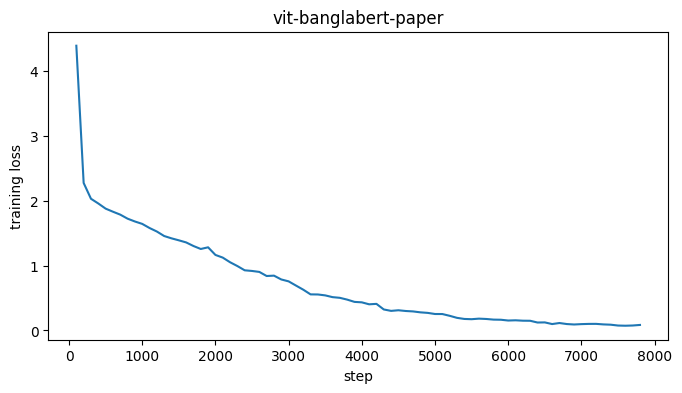

In [9]:
import matplotlib.pyplot as plt

log = pd.DataFrame([e for e in trainer.state.log_history if "loss" in e])
log.to_csv(RUN / "train_log.csv", index=False)
print(log[["step", "loss", "learning_rate", "grad_norm"]].iloc[::5].to_string(index=False))
plt.figure(figsize=(8, 4))
plt.plot(log["step"], log["loss"])
plt.xlabel("step")
plt.ylabel("training loss")
plt.title(EXPERIMENT)
plt.show()

## Test

Beam search (width 3) on 300 training crops, the validation split and the test split. The training sample shows whether the model has learned to read its own training data: low training CER with high test CER means overfitting; high CER on both means the model or decoding is at fault.

- **Plate accuracy**: share of plates whose full text is correct.
- **CER**: character edit distance / length of the true text.
- **WER**: word edit distance / number of true words (words are separated by spaces; `12-3456` is one word).

In [10]:
import time


def edit_distance(a, b):
    row = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, row[0] = row[0], i
        for j, cb in enumerate(b, 1):
            prev, row[j] = row[j], min(row[j] + 1, row[j - 1] + 1, prev + (ca != cb))
    return row[-1]


@torch.no_grad()
def read(df, batch=32):
    model.eval().to(DEVICE)
    texts, seconds = [], 0.0
    for start in range(0, len(df), batch):
        images = [Image.open(p).convert("RGB") for p in df["image"].iloc[start:start + batch]]
        pixels = processor(images, return_tensors="pt").pixel_values.to(DEVICE)
        t0 = time.perf_counter()
        out = model.generate(pixels, num_beams=NUM_BEAMS, max_new_tokens=MAX_LENGTH, no_repeat_ngram_size=0)
        seconds += time.perf_counter() - t0
        texts += [clean(t) for t in tokenizer.batch_decode(out, skip_special_tokens=True)]
    return texts, 1000 * seconds / len(df)


eval_sets = {
    "train-sample": splits["train"].sample(300, random_state=SEED),
    "val": splits["val"],
    "test": splits["test"],
}
results = []
for split, df in eval_sets.items():
    df = df.copy()
    df["predicted"], ms = read(df)
    df["correct"] = df["text"] == df["predicted"]
    df["char_errors"] = [edit_distance(t, p) for t, p in zip(df["text"], df["predicted"])]
    df["word_errors"] = [edit_distance(t.split(), p.split()) for t, p in zip(df["text"], df["predicted"])]
    for name, g in [("all", df)] + list(df.groupby("source")):
        results.append({
            "split": split, "source": name, "plates": len(g),
            "plate_accuracy": g["correct"].mean(),
            "CER": g["char_errors"].sum() / g["text"].str.len().sum(),
            "WER": g["word_errors"].sum() / g["text"].str.split().str.len().sum(),
            "empty_outputs": int((g["predicted"] == "").sum()),
            "ms_per_plate": ms,
        })
    df.to_csv(RUN / f"{split}_plates.csv", index=False)

summary = pd.DataFrame(results)
summary.to_csv(RUN / "results.csv", index=False)
print(summary.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("\nPaper (MMHQ test set, not comparable): CER 0.1323, WER 0.1068")

test = pd.read_csv(RUN / "test_plates.csv", keep_default_na=False)   # keep empty predictions as ""
print("\nExamples of wrong plates:")
print(test[~test["correct"]].head(15)[["text", "predicted"]].to_string(index=False))

       split source  plates  plate_accuracy    CER    WER  empty_outputs  ms_per_plate
train-sample    all     300          0.8967 0.0758 0.0803             20       40.5349
train-sample bd-lpr     155          0.9806 0.0198 0.0202              3       40.5349
train-sample   blpd     145          0.8069 0.1394 0.1531             17       40.5349
         val    all    1448          0.1644 0.4348 0.5360            318       42.7912
         val bd-lpr     359          0.3175 0.2132 0.3117             34       42.7912
         val   blpd    1089          0.1139 0.5126 0.6193            284       42.7912
        test    all     778          0.1555 0.4451 0.5480            179       43.6539
        test bd-lpr     218          0.3119 0.2123 0.3234             19       43.6539
        test   blpd     560          0.0946 0.5448 0.6488            160       43.6539

Paper (MMHQ test set, not comparable): CER 0.1323, WER 0.1068

Examples of wrong plates:
                 text             predic